# Загрузим готовый датасет из huggingFace 
[Ссылка](https://huggingface.co/datasets/lynx1231/historical-energy-futures-data-sample?utm_source=chatgpt.com&library=pandas) на датасет.

Датасет имеет два представления контрактов, минутные и дневные.

Мы будем использовать дневное представление контрактов

# Не много о Датасете

Датасет содержит в себе 3 основных фьючерса (дневные и минутные контракты)

1. Фьючерсы на природный газ Henry Hub
2. Фьючерсы на легкую малосернистую нефть
3. Фьючерсы на бензин RBOB

| Futures root | Exchange | Daily contracts | Minute contracts |
|---|---|---|---|
| Henry Hub Natural Gas Futures | NYMEX | NGF26, NGG26, NGH26, NGJ26 | NGF26, NGG26, NGH26, NGJ26 |
| Light Sweet Crude Oil Futures | NYMEX | CLF26, CLG26, CLH26, CLJ26 | CLF26, CLG26, CLH26, CLJ26 |
| RBOB Gasoline Futures | NYMEX | RBF26, RBG26, RBH26, RBJ26 | RBF26, RBG26, RBH26, RBJ26 |




In [35]:
import pandas as pd

df = pd.read_parquet("hf://datasets/lynx1231/historical-energy-futures-data-sample/data/daily/part-00000.parquet")

In [36]:
df.head()

,timestamp,open,high,low,close,volume,open_interest,contract_name,dataset,exchange,contract_code
0,1385510400000,5.994,5.994,5.994,5.994,0,0,Henry Hub Natural Gas Futures,Energy Futures,NYMEX,NGF26
1,1385683200000,5.984,5.984,5.984,5.984,0,0,Henry Hub Natural Gas Futures,Energy Futures,NYMEX,NGF26
2,1385942400000,6.074,6.074,6.074,6.074,0,0,Henry Hub Natural Gas Futures,Energy Futures,NYMEX,NGF26
3,1386028800000,6.188,6.188,6.188,6.188,0,0,Henry Hub Natural Gas Futures,Energy Futures,NYMEX,NGF26
4,1386115200000,6.287,6.287,6.287,6.287,0,0,Henry Hub Natural Gas Futures,Energy Futures,NYMEX,NGF26


# Описание признаков

- timestamp: Исходное целое число метки времени, нужно будет перевести в формат datetime для лучшего анализа
- open: Цена открытия минуты (первая сделка в интервале).
- high: Максимальная цена за день.
- low: Минимальная цена за день.
- close: Цена закрытия день
- volume: Объём торгов за день — сколько контрактов было проторговано.
- exchange: Биржа, где торгуется контракт
- contract_name: д конкретного контракта (root + месяц + год): NGF26 = Natural Gas, январь (F), 2026.

In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23848 entries, 0 to 23847
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   timestamp      23848 non-null  int64  
 1   open           23848 non-null  float64
 2   high           23848 non-null  float64
 3   low            23848 non-null  float64
 4   close          23848 non-null  float64
 5   volume         23848 non-null  int64  
 6   open_interest  23848 non-null  int64  
 7   contract_name  23848 non-null  str    
 8   dataset        23848 non-null  str    
 9   exchange       23848 non-null  str    
 10  contract_code  23848 non-null  str    
dtypes: float64(4), int64(3), str(4)
memory usage: 3.2 MB


In [38]:
df.shape

(23848, 11)

23848 - наблюдений, давайте переведем timestamp в datetime и посмотрим период наблюдений по каждому фьючерсу из датасета.

In [39]:
df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    utc=True
)

date_range = (
    df.groupby("contract_name")["datetime"]
      .agg(["min", "max", "count"])
      .rename(columns={"min": "start", "max": "end", "count": "rows"})
      .sort_values("start")
)
print(date_range)

                                                  start  \
contract_name                                             
Henry Hub Natural Gas Futures 2013-11-27 00:00:00+00:00   
Light Sweet Crude Oil Futures 2018-01-22 00:00:00+00:00   
RBOB Gasoline Futures         2021-12-01 00:00:00+00:00   

                                                    end   rows  
contract_name                                                   
Henry Hub Natural Gas Futures 2026-03-27 00:00:00+00:00  12284  
Light Sweet Crude Oil Futures 2026-03-20 00:00:00+00:00   8093  
RBOB Gasoline Futures         2026-03-31 00:00:00+00:00   3471  


Из вывода выше видно, что даты начала замеров по каждому фьючерсу разное, посмотрим точно количество записей на каждый фьючерс

In [40]:
df["contract_name"].value_counts()

contract_name
Henry Hub Natural Gas Futures    12284
Light Sweet Crude Oil Futures     8093
RBOB Gasoline Futures             3471
Name: count, dtype: int64

In [41]:
print("Есть ли дубликаты: ",df.duplicated().all())

Есть ли дубликаты:  False


Мы просмотрели фьючерсы, но не посмотрели их контракты, они там нам и нужны.
Построим таблицу по каждому контракту и посмотрим:
- contract_code	Код конкретного контракта
- start	Первая дата наблюдения
- end	Последняя дата наблюдения
- rows	Количество наблюдений
- zero_volume_pct	Доля строк с нулевым объёмом

In [42]:
df.groupby("contract_code").agg(
    start=("datetime", "min"),
    end=("datetime", "max"),
    rows=("datetime", "count"),
    zero_volume_pct=("volume", lambda s: (s == 0).mean())
)

,start,end,rows,zero_volume_pct
contract_code,,,,
CLF26,2018-01-22 00:00:00+00:00,2025-12-19 00:00:00+00:00,1993,0.686402
CLG26,2018-01-22 00:00:00+00:00,2026-01-20 00:00:00+00:00,2012,0.708748
CLH26,2018-01-22 00:00:00+00:00,2026-02-20 00:00:00+00:00,2034,0.699607
CLJ26,2018-01-22 00:00:00+00:00,2026-03-20 00:00:00+00:00,2054,0.737585
NGF26,2013-11-27 00:00:00+00:00,2025-12-29 00:00:00+00:00,3041,0.713252
NGG26,2013-11-27 00:00:00+00:00,2026-01-28 00:00:00+00:00,3061,0.734074
NGH26,2013-11-27 00:00:00+00:00,2026-02-25 00:00:00+00:00,3080,0.725325
NGJ26,2013-11-27 00:00:00+00:00,2026-03-27 00:00:00+00:00,3102,0.721792
RBF26,2021-12-01 00:00:00+00:00,2025-12-31 00:00:00+00:00,1026,0.586745


Скудные результаты по объему торгов, посмотрим по годам как уменьшался объем торгов

In [43]:
df['year'] = df["datetime"].dt.year
df.head()


table = df[df["contract_code"] == "CLF26"].groupby("year").agg(
    days=("datetime", "count"),
    percent_volume_zero=("volume", lambda s: (s == 0).mean()),
    mean_volume=("volume", "mean"),
)

table

,days,percent_volume_zero,mean_volume
year,,,
2018,239,1.000000,0.000000
2019,252,0.988095,0.146825
2020,253,0.992095,0.146245
2021,252,0.964286,0.837302
2022,251,0.940239,2.039841
2023,250,0.544000,26.304000
2024,252,0.055556,498.309524
2025,244,0.000000,59817.262295


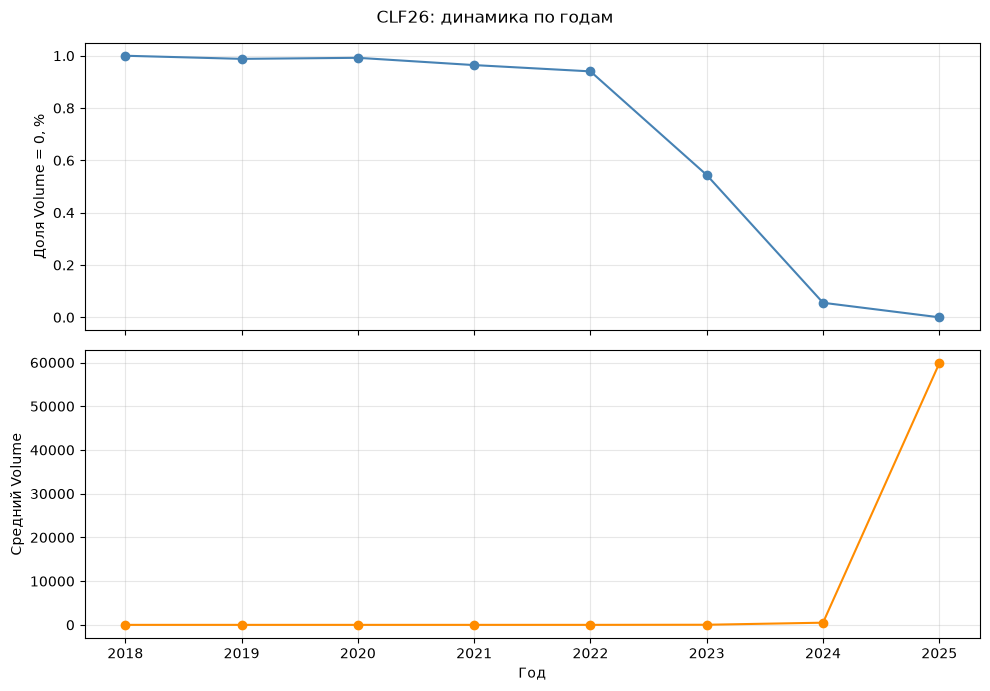

In [44]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(table.index, table["percent_volume_zero"], marker="o", color="steelblue")
axes[0].set_ylabel("Доля Volume = 0, %")
axes[0].grid(True, alpha=0.3)

axes[1].plot(table.index, table["mean_volume"], marker="o", color="darkorange")
axes[1].set_ylabel("Средний Volume")
axes[1].set_xlabel("Год")
axes[1].grid(True, alpha=0.3)

axes[1].set_xticks(table.index)          
fig.suptitle("CLF26: динамика по годам")
plt.tight_layout()
plt.show()

Посмотрим динамику по каждому контракту

CLF26, CLG26, CLH26, CLJ26.

Из графика видно, что ликвидность у конкретного контракта стала увеличиваться, только к дате экспирации.
Что в целом дает нам понимание, что для построение ML модели, нужно использовать

In [45]:
codes = ["CLF26", "CLG26", "CLH26", "CLJ26"]

daily = (
    df[df["contract_code"].isin(codes)]
    .assign(date=lambda d: d["datetime"].dt.date)
    .groupby(["contract_code", "date"], as_index=False)["volume"]
    .sum()
)
daily["date"] = pd.to_datetime(daily["date"])

daily

,contract_code,date,volume
0,CLF26,2018-01-22,0
1,CLF26,2018-01-23,0
2,CLF26,2018-01-24,0
3,CLF26,2018-01-25,0
4,CLF26,2018-01-26,0
...,...,...,...
8088,CLJ26,2026-03-16,455454
8089,CLJ26,2026-03-17,308425
8090,CLJ26,2026-03-18,157222
8091,CLJ26,2026-03-19,118719


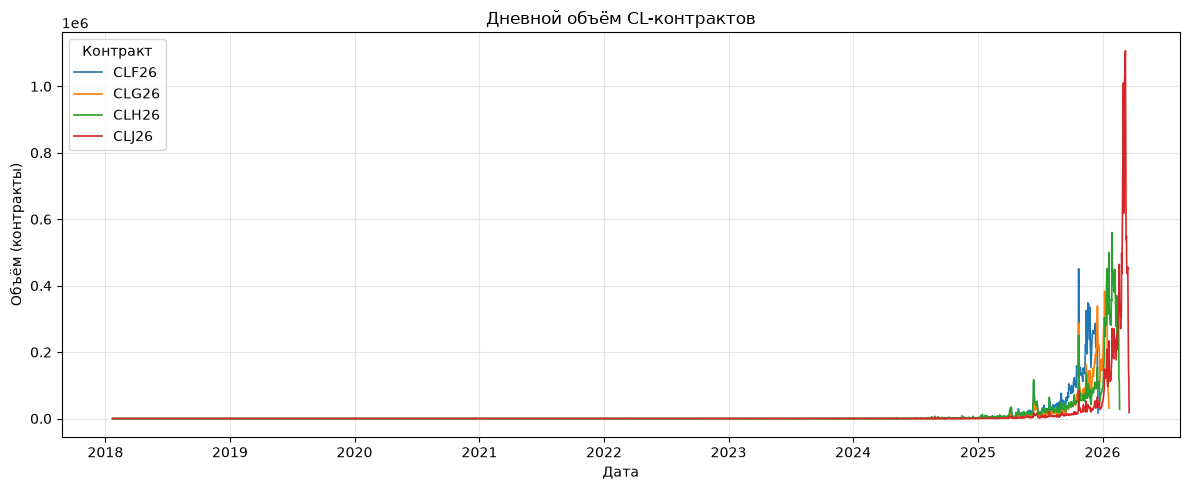

In [46]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))

for code in codes:
    sub = daily[daily["contract_code"] == code].sort_values("date")
    ax.plot(sub["date"], sub["volume"], label=code, linewidth=1.2)

ax.set_title("Дневной объём CL-контрактов")
ax.set_xlabel("Дата")
ax.set_ylabel("Объём (контракты)")
ax.legend(title="Контракт")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Результат EDA
Мы установили, что текущий набор из четырёх CL-контрактов недостаточен для построения многолетней истории ближайшего фьючерса. Поэтому для основного дневного TA baseline нам нужен другой источник.

Однако текущий датасет сохраняем для дополнительного исследования ликвидности, rollover и внутридневной реакции на новости в период активных торгов.

Следующий этап — поиск и оценка исторического Continuous Futures WTI.